# BerlinMOD in MobilitySpark

This notebook executes the BerlinMOD benchmark using MobilitySpark. There are two steps: first, the database needs to be created from the source csv files. These files are preprocessed with MobilitySpark and are partitioned depending on the experiment. Finally, the selected queries are executed by the user.

First, <code>cd</code> into the folder with the BerlinMOD files.

In [1]:
cd "../datasets/"

/usr/local/lib/python3.9/dist-packages/IPython/core/magics/osm.py:417: UserWarning: using dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


/data/PysparkMobility/datasets


In [2]:
ls -lh

total 8.8M
-rw-r--r--  1 root root  86K Jul 23 08:41 brussels_region.csv
-rw-r--r--+ 1 root root  789 Jun 13 07:32 geese.csv
-rw-r--r--  1 root root 3.3K Jul 23 08:41 instants.csv
-rw-r--r--  1 root root 1.6K Jul 23 08:42 licences.csv
-rw-r--r--  1 root root  261 Jun 17 09:52 minimini_sample_pymeos.csv
-rw-r--r--  1 root root 279K Jul 23 08:42 municipalities.csv
drwxr-xr-x  6 root root  192 Jul 23 09:21 out.csv/
drwxr-xr-x  6 root root  192 Jul 23 09:21 out.parquet/
-rw-r--r--  1 root root  13K Jul 23 08:42 periods.csv
-rw-r--r--  1 root root 5.6K Jul 23 08:42 points.csv
-rw-r--r--  1 root root 7.2K Jul 23 09:17 preproc.csv
-rw-r--r--  1 root root 148K Jul 23 08:42 regions.csv
-rw-r--r--  1 root root 6.4M Jul 23 09:03 tripsinputmini.csv
-rw-r--r--  1 root root 1.8M Jul 23 08:49 tripsinputnano.csv
-rw-r--r--  1 root root  20K Jul 23 08:42 vehicles.csv


In [3]:
rm -R spark-warehouse/

/bin/rm: cannot remove 'spark-warehouse/': No such file or directory


## Imports

Now, import the necessary libraries to the notebook.

In [4]:
from pymeos import *
from pymeos.plotters import *

from pyspark.sql import SparkSession
from pyspark.sql.types import *
import pyspark.sql.functions as F

from pysparkmeos.UDT.MeosDatatype import *

from pysparkmeos.partitions.grid_partitioner import GridPartition
from pysparkmeos.partitions.kdtree_partitioner import KDTreePartition
from pysparkmeos.partitions.adaptive_partitioner_spark import AdaptiveBinsPartitionerSpark
from pysparkmeos.partitions.approx_adaptive_partitioner import ApproximateAdaptiveBinsPartitioner

from pysparkmeos.utils.udt_appender import *
from pysparkmeos.utils.utils import *

from pysparkmeos.UDF.udf import *
from pysparkmeos.UDTF.BerlinMOD import *

from pysparkmeos.BerlinMOD.config import load_config
from pysparkmeos.BerlinMOD.queries import *
from pysparkmeos.BerlinMOD.transformation_queries import *
from pysparkmeos.BerlinMOD.partition_queries import *
from pysparkmeos.BerlinMOD.func import *

import random, datetime, os, sys
from datetime import timedelta
from functools import partial
from datetime import datetime, timezone
import contextily as cx
import distinctipy
import geopandas as gpd
import pandas as pd
import shapely.geometry as shp

import matplotlib.pyplot as plt
import numpy as np
from shapely import wkb, box, from_wkb
from typing import Union
from time import time

## Spark Initialization

In [5]:
def startspark():
    # Initialize PyMEOS
    pymeos_initialize("UTC")
    
    os.environ['PYSPARK_DRIVER_PYTHON_OPTS']= "notebook"
    os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
    os.environ['PYSPARK_PYTHON'] = sys.executable
    
    # Initialize a Spark session
    spark = SparkSession.builder \
        .appName("BerlinMOD with PySpark") \
        .master("local[3]") \
        .config("spark.default.parallelism", 12) \
        .config("spark.executor.memory", "3g") \
        .config("spark.executor.cores", 1) \
        .config("spark.driver.memory", "2g") \
        .config("spark.driver.maxResultSize", 0) \
        .config("spark.sql.execution.arrow.maxRecordsPerBatch", "500") \
        .config("spark.sql.allowMultipleTableArguments.enabled", True) \
        .getOrCreate()
        
    # Append the UDT mapping to the PyMEOS classes
    udt_append()
    
    # Get the value of 'spark.default.parallelism'
    default_parallelism = spark.sparkContext.getConf().get("spark.default.parallelism")
    print(f"spark.default.parallelism: {default_parallelism}")

    # Register udfs in Spark SQL
    register_udfs_under_spark_sql(spark)

    # Register the udtfs in Spark SQL
    register_udtfs_under_spark_sql(spark)

    return spark

spark = startspark()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
24/07/23 09:28:50 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


spark.default.parallelism: 12


24/07/23 09:28:58 WARN SimpleFunctionRegistry: The function length replaced a previously registered function.
24/07/23 09:28:58 WARN SimpleFunctionRegistry: The function nearest_approach_distance replaced a previously registered function.
----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 39040)
Traceback (most recent call last):
  File "/usr/lib/python3.9/socketserver.py", line 316, in _handle_request_noblock
    self.process_request(request, client_address)
  File "/usr/lib/python3.9/socketserver.py", line 347, in process_request
    self.finish_request(request, client_address)
  File "/usr/lib/python3.9/socketserver.py", line 360, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "/usr/lib/python3.9/socketserver.py", line 720, in __init__
    self.handle()
  File "/usr/local/lib/python3.9/dist-packages/pyspark/accumulators.py", line 295, in handle
    poll(accum_updates)
  File "/usr/local/li

## Load Tables
We will use the power of Spark SQL to read in the raw dataframes and then create the tables.

In [6]:
ls

brussels_region.csv         municipalities.csv  preproc.csv
geese.csv                   out.csv/            regions.csv
instants.csv                out.parquet/        tripsinputmini.csv
licences.csv                periods.csv         tripsinputnano.csv
minimini_sample_pymeos.csv  points.csv          vehicles.csv


## Experiments

Here you can run an experiment, select the experiment and queries to run in this notebook.  
Available experiments:
1. Run Queries AS-IS (default PySpark partitioning).
2. Run Queries with Trips partitioned by vehid, using Hash Partitioning.
3. Run Queries with Trips partitioned by trip, using RegularGrid.
4. Run Queries with Trips partitioned by trip, using KDTreePartitioning.
5. Run Queries with Trips partitioned by trip, using AdaptiveBinsPartitioning with Spark background.
6. Run Queries with Trips partitioned by trip, using ApproximateAdaptiveBinsPartitioning.

Available BerlinMOD queries:

- Total: [1, 2, 3, 4, 5, 6, 11, 12, 13, 15, 18, 20]
- Default: [3]

*Note: Some queries can consume a lot of time and memory, if you run locally, ensure to use the tripsinsputnano.csv file.*

In [7]:
# Change to your desired experiment number.
run_exp_number = 5

# Select the queries to run 
#querynumbers = [1, 2, 3, 4, 5, 6, 11, 12, 13, 15, 18, 20]
querynumbers = [3]

### Set up the configurations for the experiment

In [8]:
paths = {
    'trips': 'tripsinputmini.csv',
    'instants': 'instants.csv',
    'licences': 'licences.csv',
    'periods': 'periods.csv',
    'points': 'points.csv',
    'regions': 'regions.csv',
    'vehicles': 'vehicles.csv',
    'municipalities': 'municipalities.csv'
}

transformation_queries_simple = {
    'trips': transtripssimple2,
    'instants': transinstantssimple,
    'periods': transperiodsimple,
    'points': transpointssimple,
    'regions': transregionssimple,
    'municipalities': transmunsimple
}
        
transformation_queries = {
    'trips': transtrips2,
    'instants': transinstants,
    'periods': transperiod,
    'points': transpoints,
    'regions': transregions,
    'municipalities': transmun
}

partition_queries = {
    'trips': parttrips
}

partition_keys = {
    'trips': 'tileid'
}

num_buckets = 8
inferSchema = True
header = True

In [9]:
configs_exp1 = load_config(
    spark=spark, 
    paths=paths, 
    trans_queries=transformation_queries_simple, 
    part_queries=None, 
    partition_keys=None,
    partitioner_class=None,
    partitioner_args=None,
    num_buckets = None,
    inferSchema = inferSchema,
    header=header
)

In [10]:
configs_exp2 = load_config(
    spark=spark, 
    paths=paths, 
    trans_queries=transformation_queries_simple, 
    part_queries=None, 
    partition_keys={'trips': 'vehid'},
    partitioner_class=None,
    partitioner_args=None,
    num_buckets = num_buckets,
    inferSchema = inferSchema,
    header=header
)

In [11]:
configs_exp3 = load_config(
    spark=spark, 
    paths=paths, 
    trans_queries=transformation_queries, 
    part_queries=partition_queries, 
    partition_keys=partition_keys,
    partitioner_class=GridPartition,
    partitioner_args={'cells_per_side': 8},
    num_buckets = num_buckets,
    inferSchema = inferSchema,
    header=header
)

In [12]:
configs_exp4 = load_config(
    spark=spark, 
    paths=paths, 
    trans_queries=transformation_queries, 
    part_queries=partition_queries, 
    partition_keys=partition_keys,
    partitioner_class=KDTreePartition,
    partitioner_args={
        'moving_objects': None, 
        'dimensions': ['x', 'y', 't'], 
        'max_depth': 11},
    num_buckets = num_buckets,
    inferSchema = inferSchema,
    header=header
)

In [13]:
configs_exp5 = load_config(
    spark=spark, 
    paths=paths, 
    trans_queries=transformation_queries, 
    part_queries=partition_queries, 
    partition_keys=partition_keys,
    partitioner_class=AdaptiveBinsPartitionerSpark,
    partitioner_args={
        'spark': spark, 
        'dfname': 'tripsRaw', 
        'colname': 'trip',
        'num_tiles': 8, 
        'dimensions': ['x', 'y', 't'], 
        'utc': "UTC"},
    num_buckets = num_buckets,
    inferSchema = inferSchema,
    header=header
)

In [14]:
configs_exp6 = load_config(
    spark=spark, 
    paths=paths, 
    trans_queries=transformation_queries, 
    part_queries=partition_queries, 
    partition_keys=partition_keys,
    partitioner_class=ApproximateAdaptiveBinsPartitioner,
    partitioner_args={
        'spark': spark,
        'df': None, 
        'colname': 'trip',
        'num_tiles': 8, 
        'dimensions': ['x', 'y', 't'], 
        'utc': "UTC",
        'tablename': "tripsRaw"},
    num_buckets = num_buckets,
    inferSchema = inferSchema,
    header=header
)

In [15]:
experiment_configs = {
    i+1: config 
    for i, config in enumerate([configs_exp1, configs_exp2, configs_exp3, configs_exp4, configs_exp5, configs_exp6])
}
config = experiment_configs[run_exp_number]

queries = {
    1: querytext1,
    2: querytext2,
    3: querytext3,
    4: querytext4,
    5: querytext5,
    6: querytext6,
    11: querytext11,
    12: querytext12,
    13: querytext13,
    15: querytext15,
    18: querytext18,
    20: querytext20
}

descriptions = {
    1: querydesc1,
    2: querydesc2,
    3: querydesc3,
    4: querydesc4,
    5: querydesc5,
    6: querydesc6,
    11: querydesc11,
    12: querydesc12,
    13: querydesc13,
    15: querydesc15,
    18: querydesc18,
    20: querydesc20
}

queries_to_run = [queries[querynum] for querynum in querynumbers if querynum in queries]
descriptions_to_run = [descriptions[querynum] for querynum in querynumbers if querynum in descriptions]

### Run the experiment

#### Create Tables

In [16]:
tables, stats = load_all_tables(spark, config)

Reading raw csv  tripsinputmini.csv


Creating temp view of raw table
+------+-----+----------+-----+--------------------+--------------------+
|tripid|vehid| startdate|seqno|               point|                   t|
+------+-----+----------+-----+--------------------+--------------------+
|     1|    1|2020-06-01|    1|0101000020110F000...|2020-06-01 06:01:...|
+------+-----+----------+-----+--------------------+--------------------+

Schema and statistics of raw table
root
 |-- tripid: integer (nullable = true)
 |-- vehid: integer (nullable = true)
 |-- startdate: date (nullable = true)
 |-- seqno: integer (nullable = true)
 |-- point: string (nullable = true)
 |-- t: timestamp (nullable = true)



24/07/23 09:29:20 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-----------------+-----------------+------------------+--------------------+
|summary|           tripid|            vehid|             seqno|               point|
+-------+-----------------+-----------------+------------------+--------------------+
|  count|            67996|            67996|             67996|               67996|
|   mean|30.60521207129831|1.540825930937114|1.9983087240425907|                NULL|
| stddev|27.57892399099787|0.888352846810094|1.0294066244348008|                NULL|
|    min|                1|                1|                 1|0101000020110F000...|
|    max|               85|                3|                 6|0101000020110F000...|
+-------+-----------------+-----------------+------------------+--------------------+

Creating final table trips based on tripsRawNoCache, partitioned by tileid.


Bounds:  STBOX XT(((469819.06271261786,6586568.633572469),(498784.34433982597,6606871.682578203)),[2020-06-01 06:01:41+00, 2020-06-11 19:30:26+00))


24/07/23 09:29:43 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
24/07/23 09:29:43 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
24/07/23 09:29:43 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
24/07/23 09:29:43 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
24/07/23 09:29:43 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
24/07/23 09:29:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
24/07/23 0

... (13 outputs left out)

+-------+-----------------+--------+-----+--------+
|summary|            vehid| licence| type|   model|
+-------+-----------------+--------+-----+--------+
|  count|              632|     632|  632|     632|
|   mean|            316.5|    NULL| NULL|    NULL|
| stddev|182.5869655807884|    NULL| NULL|    NULL|
|    min|                1|B-BB 249|  bus| Acabion|
|    max|              632|B-[Y 238|truck|Wartburg|
+-------+-----------------+--------+-----+--------+

Creating final table vehicles based on vehiclesRawNoCache, partitioned by None.


Final table created in 1.5206162929534912 seconds
Final table vehicles schema:
root
 |-- vehid: integer (nullable = true)
 |-- licence: string (nullable = true)
 |-- type: string (nullable = true)
 |-- model: string (nullable = true)

Reading raw csv  municipalities.csv
Creating temp view of raw table
+--------------+----------+----------+-------+-------------+--------+----------+--------------------+
|municipalityid|      name|population|percpop|popdensitykm2|noenterp|percenterp|                geom|
+--------------+----------+----------+-------+-------------+--------+----------+--------------------+
|             1|Anderlecht|    118241|    0.1|         6680|    6460|      0.08|SRID=3857;POLYGON...|
+--------------+----------+----------+-------+-------------+--------+----------+--------------------+

Schema and statistics of raw table
root
 |-- municipalityid: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- population: integer (nullable = true)
 |-- percpop: double

+-------+-----------------+--------------------+----------------+--------------------+------------------+------------------+--------------------+--------------------+
|summary|   municipalityid|                name|      population|             percpop|     popdensitykm2|          noenterp|          percenterp|                geom|
+-------+-----------------+--------------------+----------------+--------------------+------------------+------------------+--------------------+--------------------+
|  count|               19|                  19|              19|                  19|                19|                19|                  19|                  19|
|   mean|             10.0|                NULL|         62716.0|0.052105263157894745|10740.263157894737| 4213.578947368421|0.052105263157894745|                NULL|
| stddev|5.627314338711377|                NULL|42681.7840327958|0.036297986991693114| 6302.570761576451|3406.3955912337324|0.043279318562157124|                NULL

Final table created in 54.13100337982178 seconds
Final table municipalities schema:
root
 |-- name: string (nullable = true)
 |-- municipalityid: integer (nullable = true)
 |-- tileid: integer (nullable = true)
 |-- geom: pythonuserdefined (nullable = true)



#### Execute Queries

In [17]:
qdfs_exp, stats_exp = run_all_queries(
    queries_to_run, 
    descriptions_to_run, 
    spark, 
    explain=True, 
    printplan=True
)

Query 3: Where have the vehicles with licences from QueryLicences1 been at each of the instants from QueryInstants1?
+-----+-------+---------+---+
|vehid|licence|instantid|pos|
+-----+-------+---------+---+
+-----+-------+---------+---+

Query execution time:  2.8487167358398438  seconds.
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [vehid#6219 ASC NULLS FIRST, instantid#6229 ASC NULLS FIRST], true, 0
   +- Exchange rangepartitioning(vehid#6219 ASC NULLS FIRST, instantid#6229 ASC NULLS FIRST, 200), ENSURE_REQUIREMENTS, [plan_id=5261]
      +- Project [vehid#6219, licence#6033, instantid#6229, pythonUDF0#6450 AS pos#6208]
         +- BatchEvalPython [tpoint_at(movingobject#6228, instant#6231)#6238], [pythonUDF0#6450]
            +- Project [vehid#6219, movingobject#6228, licence#6033, instantid#6229, instant#6231]
               +- Filter isnotnull(pythonUDF0#6449)
                  +- BatchEvalPython [tpoint_at(movingobject#6228, instant#6231)#6237], [pythonUDF0#6449

## Mapping the regions and trips

In [18]:
ls

brussels_region.csv         out.csv/      spark-warehouse/
geese.csv                   out.parquet/  tripsinputmini.csv
instants.csv                periods.csv   tripsinputnano.csv
licences.csv                points.csv    vehicles.csv
minimini_sample_pymeos.csv  preproc.csv
municipalities.csv          regions.csv


Text(0.5, 1.0, 'BerlinMOD Sample Trajectories Plot')

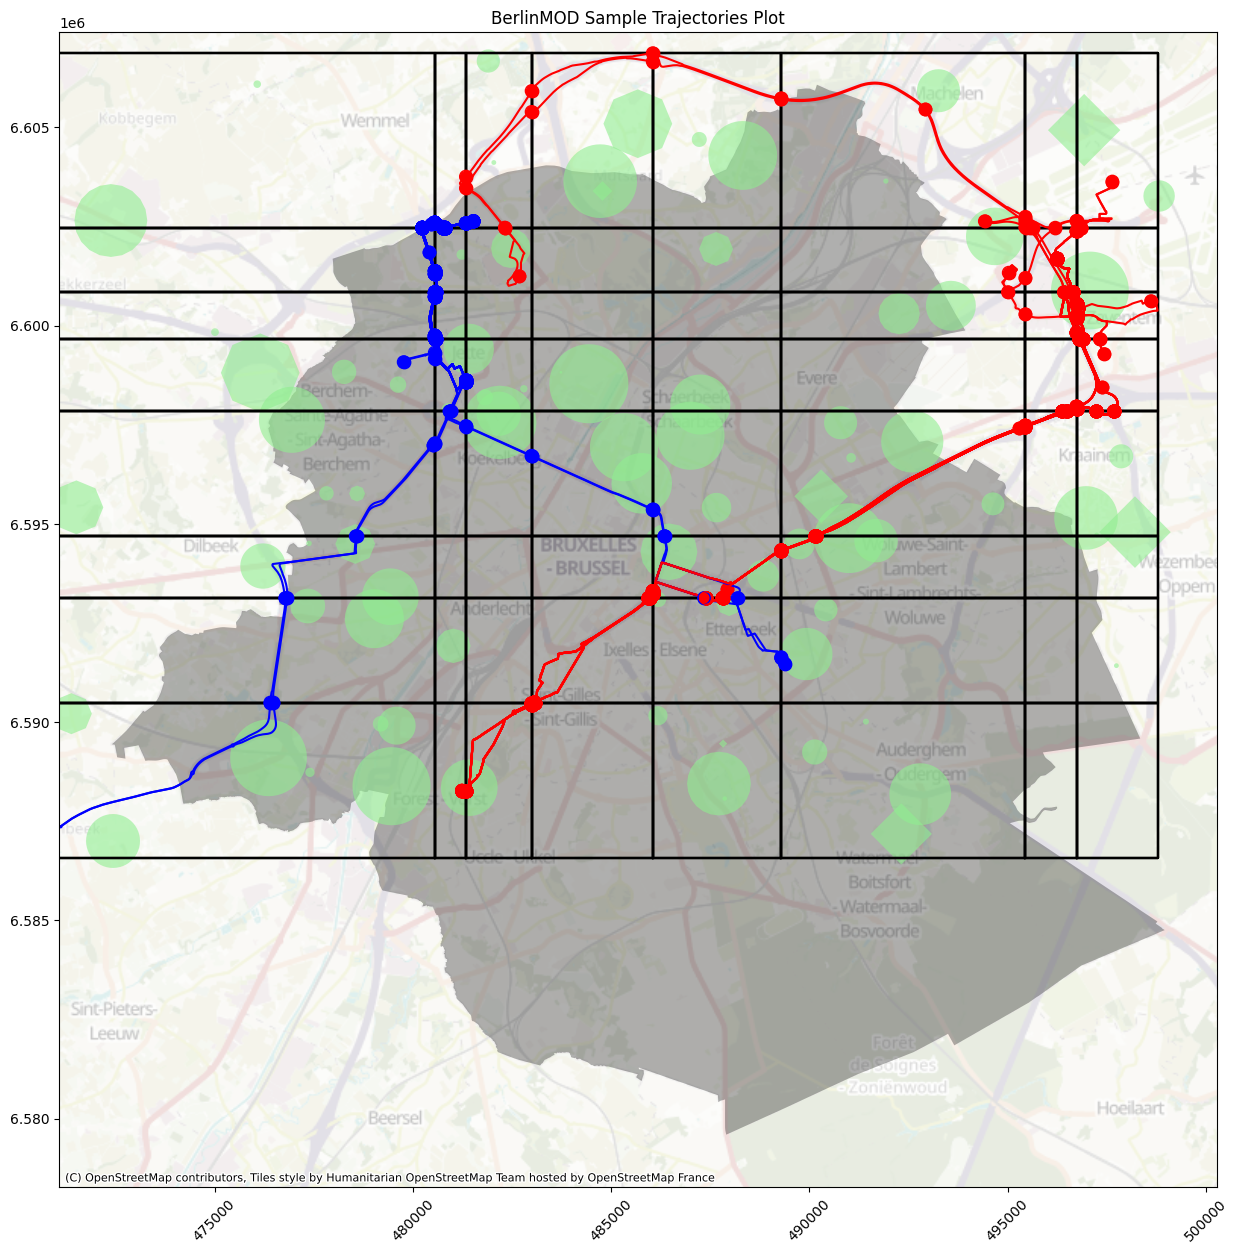

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(15, 15))
brussels = pd.read_csv(
    "brussels_region.csv", converters={"geom": partial(wkb.loads, hex=True)}
)
brussels = gpd.GeoDataFrame(brussels, geometry="geom")
brussels_geom = brussels["geom"][0]
brussels.plot(ax=ax, alpha=0.3, color='black')
cx.add_basemap(ax, alpha=0.3)
grid = spark.table('grid')

for gridrow in grid.toLocalIterator():
    gridrow.tile.plot_xy(axes=ax, color="black", draw_filling=False)

regions = spark.table('regions').select("regionid", "geom").distinct()

for regionrow in regions.toLocalIterator():
    myPoly = gpd.GeoSeries([regionrow.geom])
    myPoly.plot(ax=ax, alpha=0.6, color='lightgreen')
    
#trips = spark.table('trips').sample(0.1, seed=3).select('movingobjectid', 'movingobject')
trips = spark.table('trips').select('movingobjectid', 'movingobject', 'vehid')
colors = ['orange', 'red', 'yellow', 'blue', 'purple']
for triprow in trips.toLocalIterator():
    TemporalPointSequenceSetPlotter.plot_xy(
        triprow.movingobject, axes=ax, show_markers=True, show_grid=False, color=colors[int(triprow.vehid) % len(colors)]
    )

#extent = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
#fig.savefig(f'BerlinMODSampleplot.svg', bbox_inches=extent)  # Adjust expanded() parameters as needed

plt.title("BerlinMOD Sample Trajectories Plot")

In [20]:
jette_tiles = [
    row.tile 
    for row in spark.sql("""
        WITH tiles AS (
            SELECT DISTINCT tileid
            FROM municipalities
            WHERE name = 'Jette'
        )
        SELECT grid.* FROM grid INNER JOIN tiles ON (grid.tileid = tiles.tileid)
        """).collect()
]

auderghem_tiles = [
    row.tile 
    for row in spark.sql("""
        WITH tiles AS (
            SELECT DISTINCT tileid
            FROM municipalities
            WHERE name = 'Auderghem - Oudergem'
        )
        SELECT grid.* FROM grid INNER JOIN tiles ON (grid.tileid = tiles.tileid)
        """).collect()
]

Text(0.5, 1.0, 'BerlinMOD Sample Trajectories Plot')

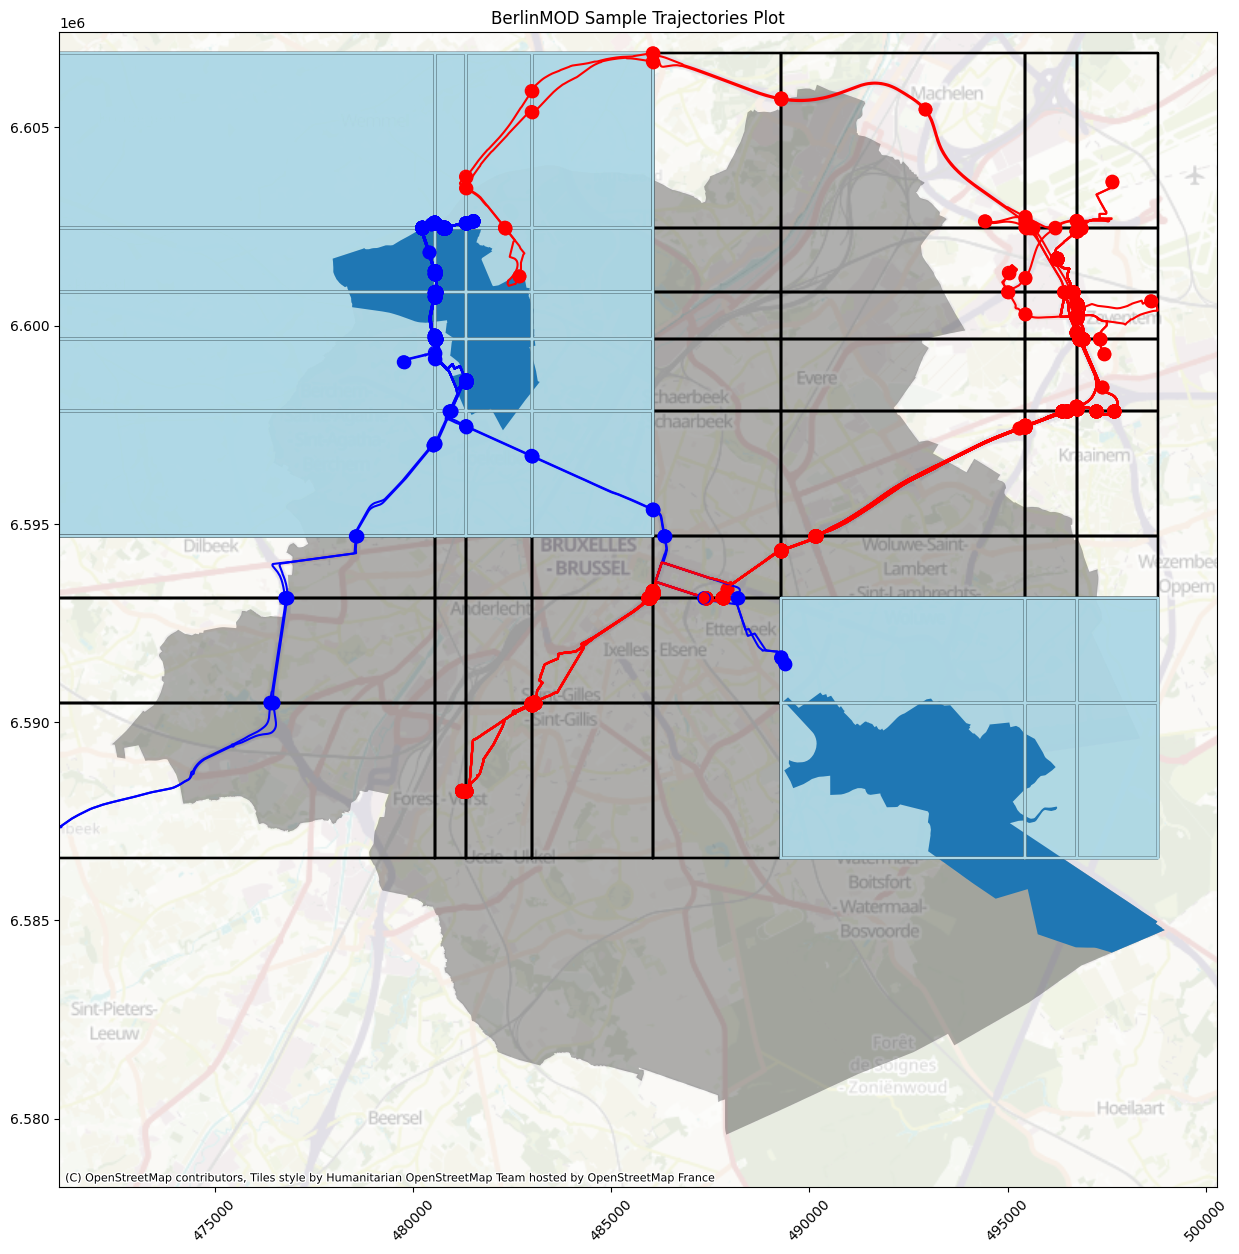

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(15, 15))
brussels = pd.read_csv(
    "brussels_region.csv", converters={"geom": partial(wkb.loads, hex=True)}
)
brussels = gpd.GeoDataFrame(brussels, geometry="geom")
brussels_geom = brussels["geom"][0]
brussels.plot(ax=ax, alpha=0.3, color='black')
cx.add_basemap(ax, alpha=0.3)
grid = spark.table('grid')

for gridrow in grid.toLocalIterator():
    gridrow.tile.plot_xy(axes=ax, color="black", draw_filling=False)

for tile in jette_tiles:
    tile.plot_xy(axes=ax, color="lightblue", draw_filling=True)

for tile in auderghem_tiles:
    tile.plot_xy(axes=ax, color="lightblue", draw_filling=True)

munis = gpd.GeoDataFrame(spark.sql("SELECT DISTINCT name, geom FROM municipalities WHERE name = 'Jette' OR name = 'Auderghem - Oudergem' LIMIT 2").toPandas(), geometry="geom")
munis.plot(ax=ax)

trips = spark.table('trips').select('movingobjectid', 'movingobject', 'vehid')
colors = ['orange', 'red', 'yellow', 'blue', 'purple']
for triprow in trips.toLocalIterator():
    TemporalPointSequenceSetPlotter.plot_xy(
        triprow.movingobject, axes=ax, show_markers=True, show_grid=False, color=colors[int(triprow.vehid) % len(colors)]
    )

#extent = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
#fig.savefig(f'BerlinMODSampleplot.svg', bbox_inches=extent)  # Adjust expanded() parameters as needed

plt.title("BerlinMOD Sample Trajectories Plot")

Text(0.5, 1.0, 'BerlinMOD Sample Trajectories Plot')

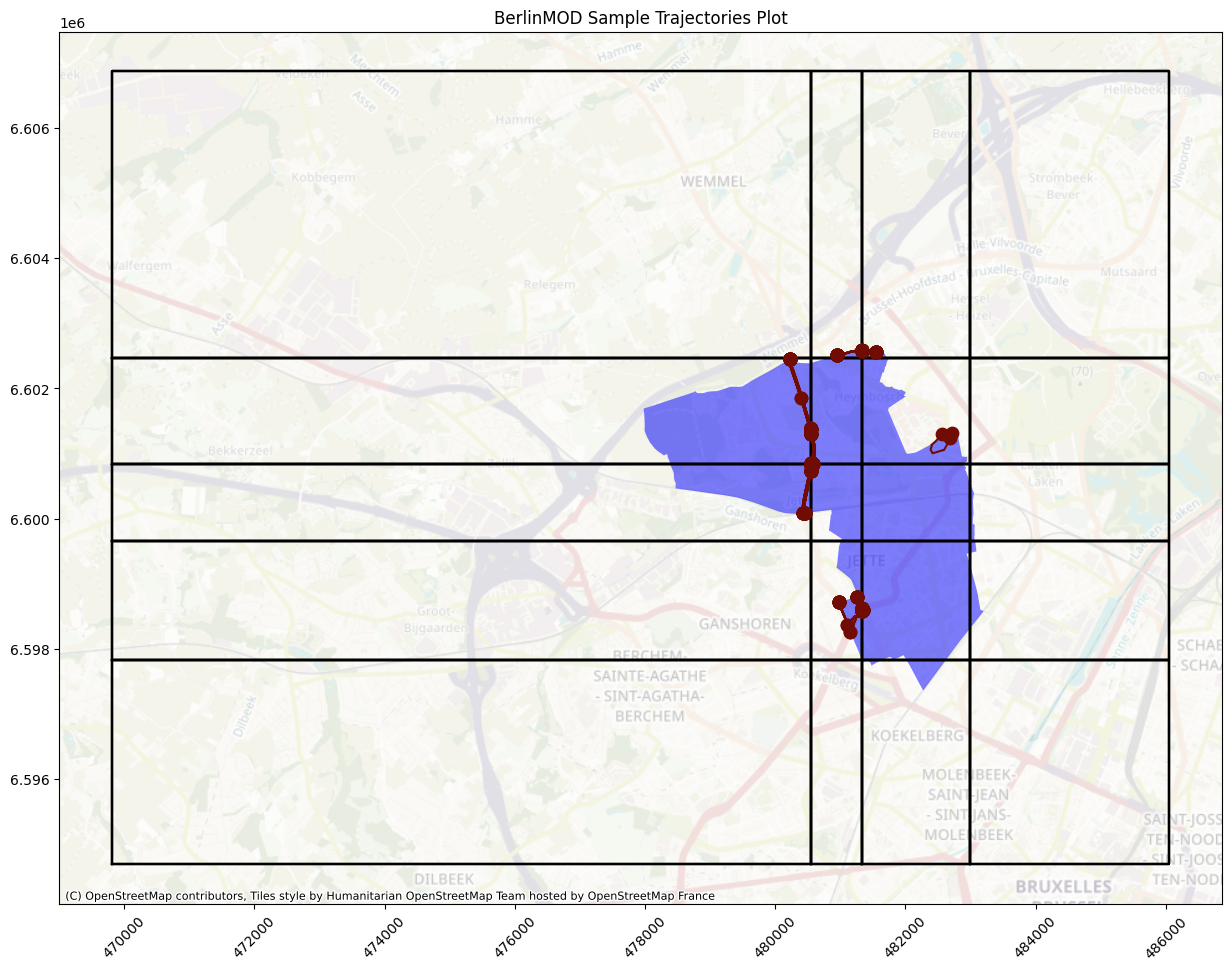

In [22]:
jette_trajs = spark.sql("""
    WITH jette AS (
        SELECT tileid, geom, municipalityid
        FROM municipalities
        WHERE name = 'Jette'
    )
    SELECT vehid, movingobjectid, movingobject, j.geom, t.tileid, j.municipalityid, at_geom(movingobject, geom) AS atgeom
    FROM trips t INNER JOIN jette j ON (t.tileid = j.tileid)
    WHERE ever_intersects(t.movingobject, j.geom) = TRUE
    ORDER BY vehid, movingobjectid, tileid
        """)

jette_tiles = [
    row.tile 
    for row in spark.sql("""
        WITH tiles AS (
            SELECT DISTINCT tileid
            FROM municipalities
            WHERE name = 'Jette'
        )
        SELECT grid.* FROM grid INNER JOIN tiles ON (grid.tileid = tiles.tileid)
        """).collect()
]

fig, ax = plt.subplots(1, 1, figsize=(15, 15))

grid = spark.table('grid')

for tile in jette_tiles:
    tile.plot_xy(axes=ax, color="black", draw_filling=False)

colors = ['orange', 'red', 'yellow', 'blue', 'purple']

for i, row in enumerate(jette_trajs.toLocalIterator()):
    if i == 0:
        geom = gpd.GeoDataFrame(jette_trajs.limit(1).toPandas(), geometry="geom")
        geom.plot(ax=ax, alpha=0.5, color='blue')
    TemporalPointSequenceSetPlotter.plot_xy(
        row.atgeom, axes=ax, show_markers=True, show_grid=False, color='#700c04'
    )
cx.add_basemap(ax, alpha=0.3)

#extent = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
#fig.savefig(f'BerlinMODSampleplot.svg', bbox_inches=extent)  # Adjust expanded() parameters as needed

plt.title("BerlinMOD Sample Trajectories Plot")